# Predicting ChlorA (Chlorophyll-a) — CalCOFI

**Goal:** Build a regression model to predict `ChlorA` (µg/L chlorophyll-a) from bottle + cast oceanographic features.

This notebook starts with data loading, field descriptions, joining on `Cst_Cnt`, and exploratory analysis.

## 1. Imports & load data

In [42]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)

DATA_DIR = "../data"
OUT_DIR = Path("model_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42


In [43]:
# Bottle = per-depth water samples; Cast = per-station cast metadata
bottle = pd.read_csv(f"{DATA_DIR}/bottle.csv", encoding="iso-8859-1", low_memory=False)
cast = pd.read_csv(f"{DATA_DIR}/cast.csv", encoding="iso-8859-1", low_memory=False)

print(f"bottle shape: {bottle.shape}")
print(f"cast shape:   {cast.shape}")
display(bottle.head(3))
display(cast.head(3))

bottle shape: (895371, 62)
cast shape:   (35644, 61)


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,C14A2q,DarkAs,DarkAp,DarkAq,MeanAs,MeanAp,MeanAq,IncTim,LightP,R_Depth,R_TEMP,R_Sal,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,0.0,10.50,233.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,8.0,10.46,232.5,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,9.0,NaN,NaN,10.0,10.46,232.8,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Cst_Cnt,Cruise_ID,Cruise,Cruz_Sta,DbSta_ID,Cast_ID,Sta_ID,Quarter,Sta_Code,Distance,Date,Year,Month,Julian_Date,Julian_Day,Time,Lat_Dec,Lat_Deg,Lat_Min,Lat_Hem,Lon_Dec,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1949-03-01-C-31CR,194903,19490305400560,5400560,19-4903CR-HY-060-0930-05400560,054.0 056.0,1,NST,NaN,03/01/1949,1949,3,17958,60,09:30:00,38.833333,38,50.0,N,-124.083333,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,2,1949-03-01-C-31CR,194903,19490305200750,5200750,19-4903CR-HY-060-2112-05200750,052.0 075.0,1,NST,NaN,03/01/1949,1949,3,17958,60,21:12:00,38.583333,38,35.0,N,-125.800000,-125,48.0,W,52.0,52.0,51.5,75.0,75.0,75.1,NaN,NaN,NaN,CREST,31CR,HY,NaN,2.0,NaN,052 75,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0,5.0,NaN,NaN,NaN,4.0,NaN,NaN,NaN
2,3,1949-03-01-C-31CR,194903,19490305100850,5100850,19-4903CR-HY-061-0354-05100850,051.0 085.0,1,NST,NaN,03/02/1949,1949,3,17959,61,03:54:00,38.475000,38,28.5,N,-126.666666,-126,40.0,W,51.0,51.0,50.3,85.0,85.0,84.7,NaN,NaN,NaN,CREST,31CR,HY,NaN,3.0,NaN,051 85,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,5.0,NaN,NaN,NaN,6.0,NaN,NaN,NaN


## 2. Field descriptions

Lookup tables describing each column in the bottle and cast tables.

In [44]:
bottle_desc = pd.read_csv(f"{DATA_DIR}/Bottle Field Descriptions.csv", encoding="iso-8859-1")
cast_desc = pd.read_csv(f"{DATA_DIR}/Cast Field Descriptions.csv", encoding="iso-8859-1")

# Drop empty trailing columns if present
bottle_desc = bottle_desc.dropna(axis=1, how="all")
cast_desc = cast_desc.dropna(axis=1, how="all")

print("=== Bottle field descriptions ===")
display(bottle_desc)

print("=== Cast field descriptions ===")
display(cast_desc)

=== Bottle field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Btl_Cnt,n.a.,"Bottle Count - All CalCOFI bottles ever sampled, consecutively numbered"
2,Sta_ID,n.a.,Line and Station [Line] [Station]
3,Depth_ID,n.a.,Uses the Cast_ID prefix ([Century]-[Year][Month][ShipCode]-[CastType][Julian Day]-[CastTime]-[Line][Sta]) but adds t...
4,Depthm,meters,Bottle depth in meters
...,...,...,...
57,TA1,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution
58,TA2,micromoles per kilogram,Total Alkalinity micromoles per kilogram solution (on a replicate sample)
59,pH1,pH scale,pH (the degree of acidity/alkalinity of a solution)
60,pH2,pH scale,pH (the degree of acidity/alkalinity of a solution) on a replicate sample


=== Cast field descriptions ===


,Field Name,Units,Description
0,Cst_Cnt,n.a.,"Cast Count - All CalCOFI casts ever conducted, consecutively numbered"
1,Cruise_ID,n.a.,Cruise identifier [Year]-[Month]-[Day]-C-[Ship Code]
2,Cruise,n.a.,Cruise Name [Year][Month]
3,Cruz_Sta,n.a.,Cruise Name and Station [Year][Month][Line][Station]
4,DbSta_ID,n.a.,Line and Station
...,...,...,...
56,Cloud_Typ,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 0500"
57,Cloud_Amt,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 2700, in oktas"
58,Visibility,n.a.,"1 Digit Code from The World Meteorlogical Organization, Code source WMO 4300"
59,Secchi,meters,Secchi disk depth in meters


## 3. Join bottle ↔ cast on `Cst_Cnt`

Each cast can have many bottles (depths). We left-join cast metadata onto every bottle row.

In [45]:
# Drop overlapping columns from cast (except join key) so we don't create _x/_y suffixes
overlap = [c for c in cast.columns if c in bottle.columns and c != "Cst_Cnt"]
print("Overlapping columns (kept from bottle, cast versions dropped):", overlap)

cast_for_join = cast.drop(columns=overlap)
df = bottle.merge(cast_for_join, on="Cst_Cnt", how="left")

print(f"\nJoined shape: {df.shape}")
print(f"Rows with ChlorA present: {df['ChlorA'].notna().sum():,} / {len(df):,}")
print(f"Unmatched casts (null Year after join): {df['Year'].isna().sum():,}")
df.head(3)

Overlapping columns (kept from bottle, cast versions dropped): ['Sta_ID']

Joined shape: (895371, 121)
Rows with ChlorA present: 245,666 / 895,371
Unmatched casts (null Year after join): 0


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,RecInd,T_prec,T_qual,S_prec,S_qual,P_qual,O_qual,SThtaq,O2Satq,ChlorA,Chlqua,Phaeop,Phaqua,PO4uM,PO4q,SiO3uM,SiO3qu,NO2uM,NO2q,NO3uM,NO3q,NH3uM,NH3q,C14As1,C14A1p,C14A1q,C14As2,C14A2p,...,Lon_Deg,Lon_Min,Lon_Hem,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Ship_Name,Ship_Code,Data_Type,Order_Occ,Event_Num,Cruz_Leg,Orig_Sta_ID,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,TimeZone,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,NaN,NaN,3,1.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,NaN,NaN,3,2.0,NaN,2.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,NaN,NaN,7,2.0,NaN,3.0,NaN,9.0,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,NaN,NaN,9.0,NaN,NaN,...,-124,5.0,W,54.0,54.0,53.8,56.0,56.0,55.8,NaN,NaN,NaN,CREST,31CR,HY,NaN,1.0,NaN,054 56,NaN,4903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,18.0,NaN,NaN,NaN,2.0,NaN,NaN,NaN


## 4. Exploratory Data Analysis

We work with rows that have a measured `ChlorA` value. Quality-code / precision columns (`*q`, `*_qual`, `*_prec`) are dropped from the correlation view so the heatmap stays readable.

In [46]:
# Subset to samples with ChlorA measured
eda = df[df["ChlorA"].notna()].copy()
print(f"EDA subset (ChlorA not null): {eda.shape}")

# Identify numeric columns useful for correlation (skip IDs / quality codes)
skip_patterns = ("Cnt", "qual", "qua", "prec", "ID", "Code", "Num", "Ind", "Ap", "Aq", "pH")
numeric_cols = eda.select_dtypes(include=[np.number]).columns.tolist()

def is_useful_feature(col: str) -> bool:
    if col in ("Cst_Cnt", "Btl_Cnt", "Cruise", "Cruz_Sta", "DbSta_ID", "Julian_Date", "Julian_Day"):
        return False
    # quality / precision columns
    if col.endswith("q") or col.endswith("qua") or col.endswith("_qual") or col.endswith("_prec"):
        return False
    # C14 precision columns like C14A1p, MeanAp, DarkAp
    if col.endswith("Ap") or col in ("C14A1p", "C14A2p"):
        return False
    return True

corr_cols = [c for c in numeric_cols if is_useful_feature(c)]
# Prefer columns with decent coverage
coverage = eda[corr_cols].notna().mean()
corr_cols = coverage[coverage >= 0.05].index.tolist()
print(f"Numeric features used in heatmap: {len(corr_cols)}")
print(corr_cols)

EDA subset (ChlorA not null): (245666, 121)
Numeric features used in heatmap: 64
['Depthm', 'T_degC', 'Salnty', 'O2ml_L', 'STheta', 'O2Sat', 'Oxy_µmol/Kg', 'BtlNum', 'RecInd', 'ChlorA', 'Phaeop', 'PO4uM', 'SiO3uM', 'NO2uM', 'NO3uM', 'NH3uM', 'C14As1', 'C14As2', 'DarkAs', 'MeanAs', 'LightP', 'R_Depth', 'R_TEMP', 'R_Sal', 'R_DYNHT', 'R_Nuts', 'R_Oxy_µmol/Kg', 'Quarter', 'Distance', 'Year', 'Month', 'Lat_Dec', 'Lat_Deg', 'Lat_Min', 'Lon_Dec', 'Lon_Deg', 'Lon_Min', 'Rpt_Line', 'St_Line', 'Ac_Line', 'Rpt_Sta', 'St_Station', 'Ac_Sta', 'Bottom_D', 'Secchi', 'ForelU', 'Order_Occ', 'Event_Num', 'Cruz_Leg', 'IntChl', 'IntC14', 'TimeZone', 'Wave_Dir', 'Wave_Ht', 'Wave_Prd', 'Wind_Dir', 'Wind_Spd', 'Barometer', 'Dry_T', 'Wet_T', 'Wea', 'Cloud_Typ', 'Cloud_Amt', 'Visibility']


### 4.1 Correlation heatmap (numerical features)

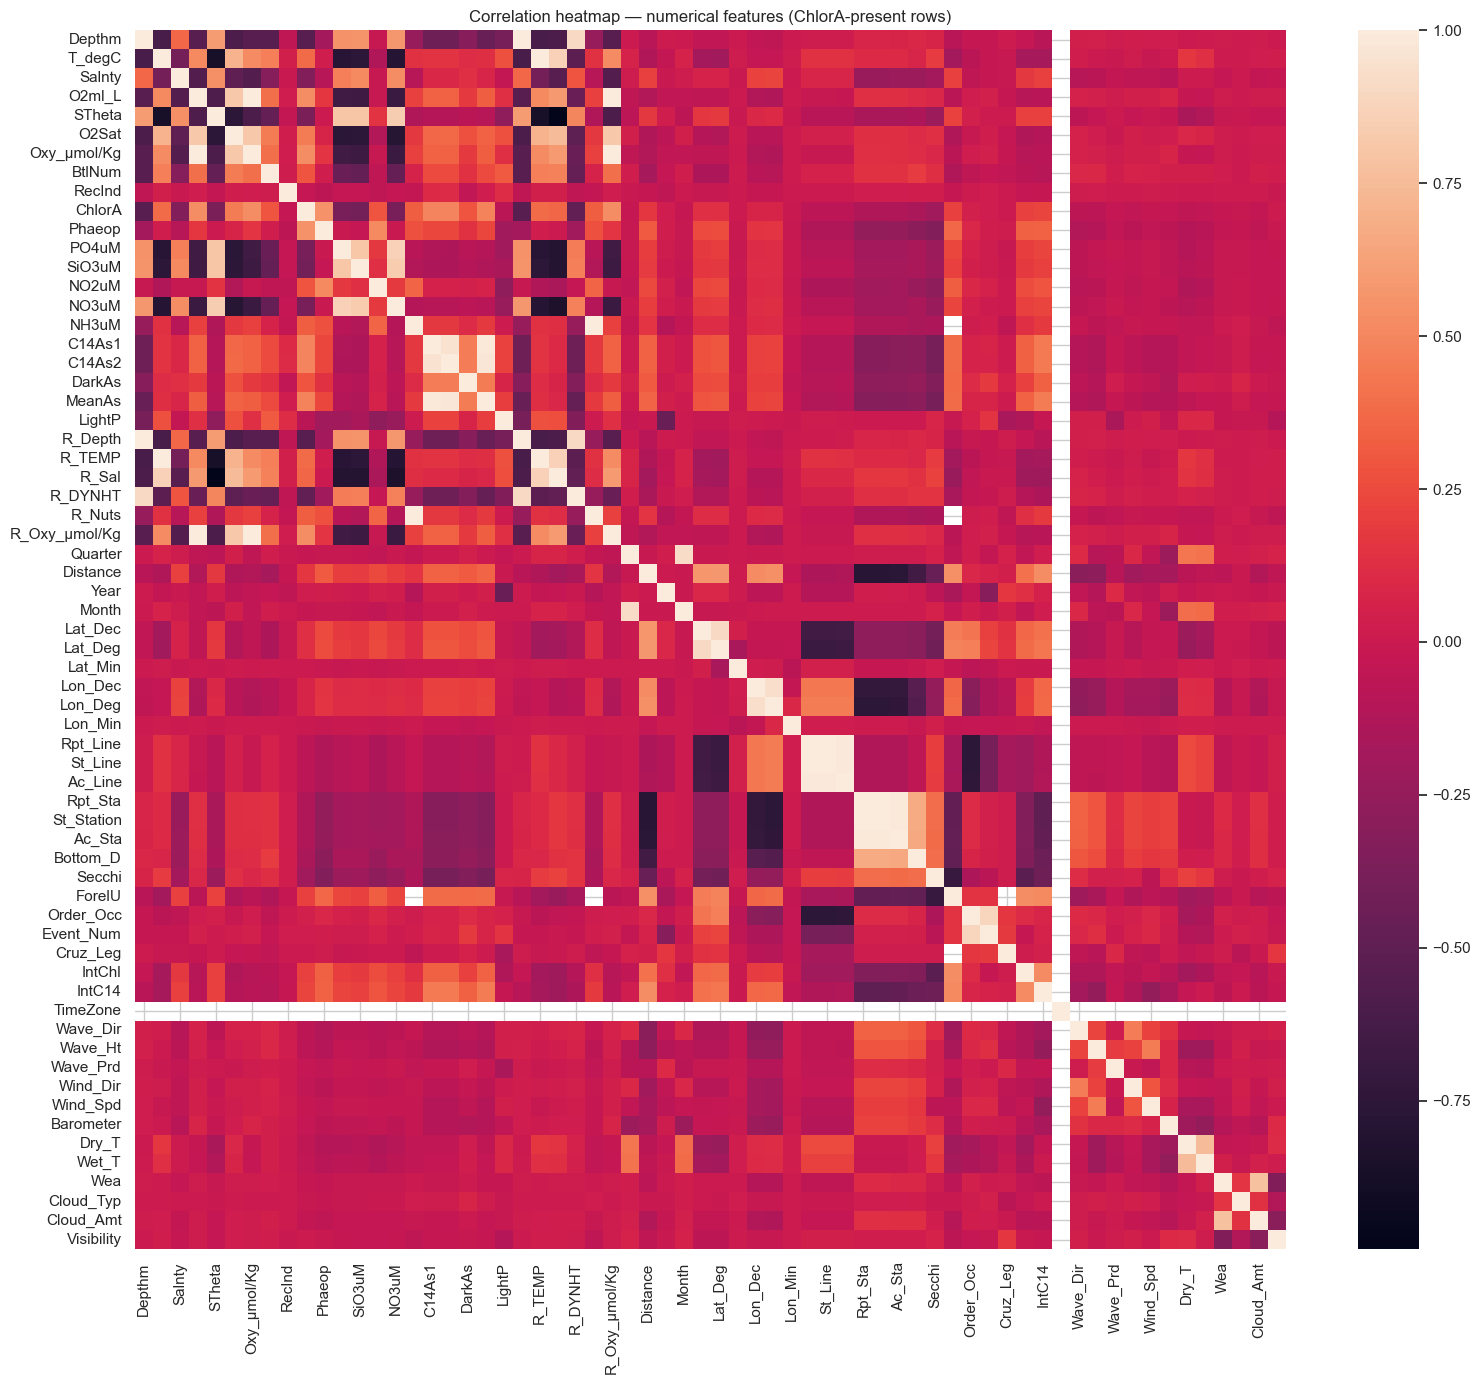

Top |correlations| with ChlorA:


,corr_with_ChlorA
Phaeop,0.550099
R_Oxy_µmol/Kg,0.527621
Oxy_µmol/Kg,0.527615
O2ml_L,0.527086
Depthm,-0.526361
R_Depth,-0.526356
R_DYNHT,-0.492949
C14As1,0.487610
C14As2,0.487108
MeanAs,0.480664


In [47]:
corr = eda[corr_cols].corr(method="kendall",numeric_only=True)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    corr,

)
ax.set_title("Correlation heatmap — numerical features (ChlorA-present rows)")
plt.tight_layout()
plt.show()

# ChlorA correlations ranked
if "ChlorA" in corr.columns:
    chlora_corr = corr["ChlorA"].drop("ChlorA").sort_values(key=abs, ascending=False)
    print("Top |correlations| with ChlorA:")
    display(chlora_corr.head(15).to_frame("corr_with_ChlorA"))

In [48]:
whatis('Phaeop',bottle_desc)

23    Micrograms Phaeopigment per liter seawater, measured fluormetrically
Name: Description, dtype: object


### 4.2 Distance from coast vs ChlorA (hue = Month)

`Distance` is nautical miles from the coast intercept (cast-level). Colored by calendar month to show seasonal structure.

Rows with Distance + ChlorA + Month: 225,955


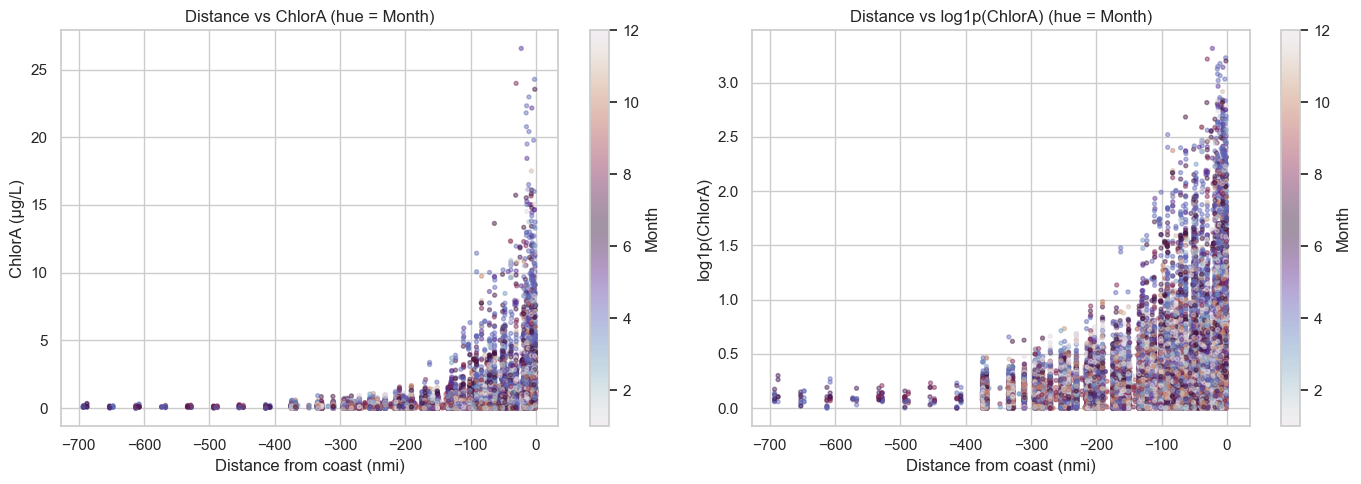

,n,mean_ChlorA,mean_Distance
Month,,,
1,36018,0.361627,-128.184559
2,16930,0.403491,-120.227542
3,11468,0.388642,-121.450509
4,39528,0.650074,-128.740015
5,10166,0.703472,-113.294446
6,4000,0.466945,-150.447996
7,32808,0.466763,-128.538742
8,17616,0.421576,-131.293397
9,6884,0.285859,-135.723588


In [49]:
dist_plot = eda[["Distance", "ChlorA", "Month"]].dropna()
print(f"Rows with Distance + ChlorA + Month: {len(dist_plot):,}")

# Sample for readability if very large
if len(dist_plot) > 40_000:
    dist_plot = dist_plot.sample(40_000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Distance vs ChlorA, colored by month
sc = axes[0].scatter(
    dist_plot["Distance"],
    dist_plot["ChlorA"],
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
cb = fig.colorbar(sc, ax=axes[0], label="Month")
axes[0].set_xlabel("Distance from coast (nmi)")
axes[0].set_ylabel("ChlorA (µg/L)")
axes[0].set_title("Distance vs ChlorA (hue = Month)")

# Same relationship on log1p(ChlorA) — chlorophyll is heavily right-skewed
sc2 = axes[1].scatter(
    dist_plot["Distance"],
    np.log1p(dist_plot["ChlorA"]),
    c=dist_plot["Month"],
    cmap="twilight",
    s=8,
    alpha=0.45,
)
fig.colorbar(sc2, ax=axes[1], label="Month")
axes[1].set_xlabel("Distance from coast (nmi)")
axes[1].set_ylabel("log1p(ChlorA)")
axes[1].set_title("Distance vs log1p(ChlorA) (hue = Month)")

plt.tight_layout()
plt.show()

# Monthly summary
monthly = (
    eda.dropna(subset=["Distance", "ChlorA", "Month"])
    .groupby("Month")
    .agg(n=("ChlorA", "size"), mean_ChlorA=("ChlorA", "mean"), mean_Distance=("Distance", "mean"))
)
display(monthly)

## 5. Feature engineering & missing values

Fill NAs for the top ChlorA correlates, derive **Line / Station**, **NSM** (seconds since midnight), and one-hot encode **Month** and **Day**.


In [50]:
# Resolve oxygen column names (mu character can vary by encoding)
def col_containing(df, *parts):
    for c in df.columns:
        if all(p in c for p in parts):
            return c
    raise KeyError(f"No column containing {parts}")

OXY_UMOL = col_containing(df, "Oxy_", "mol/Kg")
R_OXY_UMOL = col_containing(df, "R_Oxy")

TOP_CORR_FEATURES = [
    "Phaeop",
    R_OXY_UMOL,
    OXY_UMOL,
    "O2ml_L",
    "Depthm",
    "R_Depth",
    "R_DYNHT",
    "O2Sat",
    "SiO3uM",
    "NO3uM",
    "T_degC",
]

print("Top-correlation feature columns:")
for c in TOP_CORR_FEATURES:
    print(f"  {c!r}")

# Work only on rows with ChlorA target
model_df = df[df["ChlorA"].notna()].copy()

# --- Line & Station from Sta_ID ("090.0 045.0") ---
sta_parts = model_df["Sta_ID"].astype(str).str.strip().str.split(expand=True)
model_df["Line"] = pd.to_numeric(sta_parts[0], errors="coerce")
model_df["Station"] = pd.to_numeric(sta_parts[1], errors="coerce")

# --- Day of month from Date; NSM from Time ---
model_df["Date_parsed"] = pd.to_datetime(model_df["Date"], errors="coerce")
model_df["Day"] = model_df["Date_parsed"].dt.day

def time_to_nsm(t):
    """Number of Seconds since Midnight."""
    if pd.isna(t):
        return np.nan
    try:
        parts = str(t).split(":")
        h, m = int(parts[0]), int(parts[1])
        s = float(parts[2]) if len(parts) > 2 else 0.0
        return h * 3600 + m * 60 + s
    except Exception:
        return np.nan

model_df["NSM"] = model_df["Time"].map(time_to_nsm)

print(f"Rows with ChlorA: {len(model_df):,}")
print("NA rates (before impute) for top correlates + time/location:")
display(
    model_df[TOP_CORR_FEATURES + ["Line", "Station", "Month", "Day", "NSM"]]
    .isna().mean()
    .sort_values(ascending=False)
    .to_frame("frac_na")
)

Top-correlation feature columns:
  'Phaeop'
  'R_Oxy_µmol/Kg'
  'Oxy_µmol/Kg'
  'O2ml_L'
  'Depthm'
  'R_Depth'
  'R_DYNHT'
  'O2Sat'
  'SiO3uM'
  'NO3uM'
  'T_degC'
Rows with ChlorA: 245,666
NA rates (before impute) for top correlates + time/location:


,frac_na
NO3uM,0.043661
SiO3uM,0.041117
R_Oxy_µmol/Kg,0.018415
Oxy_µmol/Kg,0.018415
O2Sat,0.018403
O2ml_L,0.014788
R_DYNHT,0.014434
T_degC,0.012590
Phaeop,0.000020
R_Depth,0.000004


In [51]:
# Median-impute top ChlorA correlates (+ Line/Station/NSM if needed)
IMPUTE_COLS = TOP_CORR_FEATURES + ["Line", "Station", "NSM"]
impute_values = model_df[IMPUTE_COLS].median(numeric_only=True)

model_df[IMPUTE_COLS] = model_df[IMPUTE_COLS].fillna(impute_values)

# Month / Day must be present for OHE - drop rare rows still missing them
before = len(model_df)
model_df = model_df.dropna(subset=["Month", "Day", "Line", "Station", "Sta_ID"]).copy()
model_df["Month"] = model_df["Month"].astype(int)
model_df["Day"] = model_df["Day"].astype(int)
print(f"Dropped {before - len(model_df):,} rows missing Month/Day/Line/Station")
print(f"Modeling rows: {len(model_df):,}")

# One-hot encode Month and Day
month_ohe = pd.get_dummies(model_df["Month"], prefix="Month")
day_ohe = pd.get_dummies(model_df["Day"], prefix="Day")
model_df = pd.concat([model_df, month_ohe, day_ohe], axis=1)

MONTH_COLS = month_ohe.columns.tolist()
DAY_COLS = day_ohe.columns.tolist()
model_df[MONTH_COLS + DAY_COLS] = model_df[MONTH_COLS + DAY_COLS].astype(float)
print(f"Month OHE cols: {len(MONTH_COLS)}, Day OHE cols: {len(DAY_COLS)}")

# Feature sets
PHYSICAL_CONTINUOUS = ["T_degC", "Depthm", "R_Depth", "R_DYNHT", "Line", "Station", "NSM"]
CHEMICAL = ["Phaeop", R_OXY_UMOL, OXY_UMOL, "O2ml_L", "O2Sat", "SiO3uM", "NO3uM"]

physical_features = PHYSICAL_CONTINUOUS + MONTH_COLS + DAY_COLS
chemical_physical_features = physical_features + CHEMICAL

print(f"Physical feature count: {len(physical_features)}")
print(f"Chemical+physical feature count: {len(chemical_physical_features)}")

Dropped 0 rows missing Month/Day/Line/Station
Modeling rows: 245,666
Month OHE cols: 12, Day OHE cols: 31
Physical feature count: 50
Chemical+physical feature count: 57


## 6. Per-station train / test split

For **each** `Sta_ID`, hold out ~20% of that station's bottles for test (so every station with >=2 samples contributes to both sets). Random row splits are not used.


In [52]:
def station_train_test_split(frame, station_col="Sta_ID", test_size=0.2, random_state=RANDOM_STATE):
    """Split recordings within each station (not a global random split)."""
    rng = np.random.RandomState(random_state)
    train_idx, test_idx = [], []

    for _, group in frame.groupby(station_col):
        idx = group.index.to_numpy()
        if len(idx) == 1:
            train_idx.append(idx[0])
            continue
        n_test = max(1, int(round(len(idx) * test_size)))
        n_test = min(n_test, len(idx) - 1)  # keep >=1 in train
        chosen = rng.choice(idx, size=n_test, replace=False)
        test_idx.extend(chosen.tolist())
        train_idx.extend(np.setdiff1d(idx, chosen).tolist())

    return frame.loc[train_idx].copy(), frame.loc[test_idx].copy()

train_df, test_df = station_train_test_split(model_df)

print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")
print(f"Stations in train: {train_df['Sta_ID'].nunique()} | in test: {test_df['Sta_ID'].nunique()}")
print(
    f"Stations in both: {len(set(train_df['Sta_ID']) & set(test_df['Sta_ID']))}"
)

y_train = train_df["ChlorA"]
y_test = test_df["ChlorA"]

X_train_phys = train_df[physical_features]
X_test_phys = test_df[physical_features]
X_train_both = train_df[chemical_physical_features]
X_test_both = test_df[chemical_physical_features]

print("Physical X_train:", X_train_phys.shape, "| Both X_train:", X_train_both.shape)

Train: 196,481 | Test: 49,185
Stations in train: 1052 | in test: 896
Stations in both: 896
Physical X_train: (196481, 50) | Both X_train: (196481, 57)


## 7. Train all models (`_train_all_models.py`)

Train **all 10 regressors** with **`GridSearchCV`** on both feature sets:

1. **Physical only** - T_degC, Depthm, R_Depth, R_DYNHT, Line, Station, NSM, Month/Day OHE
2. **Physical + chemical** - above + Phaeop, oxygen, SiO3uM, NO3uM

Results are checkpointed to `model_results/` after each model (~5-10 min total).


In [53]:
def make_models_and_params():
    """Each model is wrapped in GridSearchCV with an explicit hyperparameter grid."""
    return {
        "Linear Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", LinearRegression())]),
            {"model__fit_intercept": [True, False]},
        ),
        "Ridge Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Ridge())]),
            {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        ),
        "Lasso Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", Lasso(max_iter=8000))]),
            {"model__alpha": [0.001, 0.01, 0.1, 1.0]},
        ),
        "ElasticNet Regression": (
            Pipeline([("scaler", MinMaxScaler()), ("model", ElasticNet(max_iter=8000))]),
            {"model__alpha": [0.01, 0.1, 1.0], "model__l1_ratio": [0.2, 0.5, 0.8]},
        ),
        "Polynomial Regression": (
            Pipeline([
                ("poly", PolynomialFeatures(include_bias=False)),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]),
            {"poly__degree": [2, 3], "model__alpha": [1.0, 10.0, 100.0]},
        ),
        "Decision Tree Regressor": (
            Pipeline([("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
            {"model__max_depth": [3, 5, 10, 20, None]},
        ),
        "Random Forest Regressor": (
            Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
            {"model__n_estimators": [50, 100, 200]},
        ),
        "Gradient Boosting Regressor": (
            Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
            {"model__learning_rate": [0.01, 0.05, 0.1], "model__n_estimators": [100, 200]},
        ),
        "Support Vector Regressor (SVR)": (
            Pipeline([("scaler", MinMaxScaler()), ("model", SVR())]),
            {"model__C": [0.1, 1.0, 10.0], "model__kernel": ["linear", "rbf"]},
        ),
        "K-Nearest Neighbors Regressor": (
            Pipeline([("scaler", MinMaxScaler()), ("model", KNeighborsRegressor(n_jobs=-1))]),
            {"model__n_neighbors": [3, 5, 7, 11]},
        ),
    }


def evaluate(y_true, y_pred):
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }


def train_model_zoo(X_train, y_train, X_test, y_test, label, svr_max_rows=8000):
    """GridSearchCV over all 10 models; checkpoint metrics CSV after each fit."""
    results = []
    fitted = {}
    models = make_models_and_params()

    for name, (pipe, params) in models.items():
        print(f"[{label}] Training {name} ...", flush=True)
        t1 = time.time()
        Xt, yt = X_train, y_train
        X_eval = X_test

        # Polynomial: continuous physical cols only (skip Month/Day OHE)
        if name == "Polynomial Regression":
            cont_cols = [c for c in PHYSICAL_CONTINUOUS if c in X_train.columns]
            Xt, yt = X_train[cont_cols], y_train
            X_eval = X_test[cont_cols]

        # SVR: subsample for tractable runtime
        if "SVR" in name and len(Xt) > svr_max_rows:
            sample_idx = yt.sample(svr_max_rows, random_state=RANDOM_STATE).index
            Xt = Xt.loc[sample_idx]
            yt = yt.loc[sample_idx]
            print(f"  (SVR subsampled to {svr_max_rows})", flush=True)

        # KNN: subsample train for speed at this scale
        if "K-Nearest" in name and len(Xt) > 30000:
            sample_idx = yt.sample(30000, random_state=RANDOM_STATE).index
            Xt = Xt.loc[sample_idx]
            yt = yt.loc[sample_idx]
            print("  (KNN subsampled to 30000 train rows)", flush=True)

        grid = GridSearchCV(
            estimator=pipe,
            param_grid=params,
            cv=3,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True,
            return_train_score=True,
        )
        grid.fit(Xt, yt)
        best = grid.best_estimator_
        pred = best.predict(X_eval)
        metrics = evaluate(y_test, pred)

        row = {
            "feature_set": label,
            "model": name,
            **metrics,
            "best_params": json.dumps(grid.best_params_),
            "best_cv_rmse": float(-grid.best_score_),
            "seconds": round(time.time() - t1, 1),
        }
        results.append(row)
        fitted[name] = best

        print(
            f"  -> R2={metrics['R2']:.4f} RMSE={metrics['RMSE']:.4f} "
            f"MAE={metrics['MAE']:.4f} ({row['seconds']}s) params={grid.best_params_}",
            flush=True,
        )
        pd.DataFrame(results).to_csv(OUT_DIR / f"metrics_{label}.csv", index=False)

    return pd.DataFrame(results), fitted

### 7.1 Train all models on both feature sets


In [53]:
# --- train physical-only, then physical + chemical (same as _train_all_models.py) ---
phys_metrics, phys_models = train_model_zoo(
    X_train_phys, y_train, X_test_phys, y_test, label="physical"
)
both_metrics, both_models = train_model_zoo(
    X_train_both, y_train, X_test_both, y_test, label="phys+chem"
)

all_metrics = pd.concat([phys_metrics, both_metrics], ignore_index=True)
all_metrics.to_csv(OUT_DIR / "metrics_all.csv", index=False)
print("\nSaved:", OUT_DIR / "metrics_all.csv")

print("\n=== Physical-only (sorted by R2) ===")
display(
    phys_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

print("\n=== Physical + chemical (sorted by R2) ===")
display(
    both_metrics.sort_values("R2", ascending=False)[
        ["model", "R2", "RMSE", "MAE", "best_cv_rmse", "best_params", "seconds"]
    ]
)

[physical] Training Linear Regression ...
  -> R2=0.1411 RMSE=1.1295 MAE=0.4759 (4.7s) params={'model__fit_intercept': False}
[physical] Training Ridge Regression ...
  -> R2=0.1342 RMSE=1.1340 MAE=0.4747 (4.7s) params={'model__alpha': 100.0}
[physical] Training Lasso Regression ...
  -> R2=0.1339 RMSE=1.1342 MAE=0.4700 (3.5s) params={'model__alpha': 0.001}
[physical] Training ElasticNet Regression ...
  -> R2=0.1094 RMSE=1.1501 MAE=0.4448 (3.9s) params={'model__alpha': 0.01, 'model__l1_ratio': 0.2}
[physical] Training Polynomial Regression ...
  -> R2=0.2222 RMSE=1.0748 MAE=0.4307 (4.1s) params={'model__alpha': 100.0, 'poly__degree': 2}
[physical] Training Decision Tree Regressor ...
  -> R2=0.4171 RMSE=0.9304 MAE=0.2665 (3.6s) params={'model__max_depth': 10}
[physical] Training Random Forest Regressor ...



KeyboardInterrupt


KeyboardInterrupt



### 7.2 Compare feature sets


In [ ]:
phys_idx = phys_metrics.set_index("model")
both_idx = both_metrics.set_index("model")

compare = phys_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys)").join(
    both_idx[["R2", "RMSE", "MAE"]].add_suffix(" (phys+chem)")
)
compare["R2_lift"] = compare["R2 (phys+chem)"] - compare["R2 (phys)"]
compare = compare.sort_values("R2 (phys+chem)", ascending=False)
display(compare)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(compare))
w = 0.35
ax.bar(x - w / 2, compare["R2 (phys)"], width=w, label="Physical only")
ax.bar(x + w / 2, compare["R2 (phys+chem)"], width=w, label="Physical + chemical")
ax.set_xticks(x)
ax.set_xticklabels(compare.index, rotation=55, ha="right", fontsize=8)
ax.set_ylabel("Test R2")
ax.set_title("ChlorA regression - physical vs physical+chemical")
ax.legend()
ax.axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

# Feature importance from best Random Forest (phys+chem)
tree_name = "Random Forest Regressor"
if tree_name in both_models:
    rf = both_models[tree_name].named_steps["model"]
    imp = (
        pd.Series(rf.feature_importances_, index=chemical_physical_features)
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    imp.head(20).sort_values().plot(
        kind="barh", ax=ax, color=sns.color_palette("colorblind")[0]
    )
    ax.set_xlabel("Importance")
    ax.set_title(f"{tree_name} - top 20 feature importances (phys+chem)")
    plt.tight_layout()
    plt.show()
    display(imp.head(15).to_frame("importance"))

### 7.3 Load saved results (optional)

If you already ran training (or `_train_all_models.py`), load the CSV instead of re-fitting.


In [ ]:
# Uncomment to reload without retraining:
# all_metrics = pd.read_csv(OUT_DIR / "metrics_all.csv")
# phys_metrics = all_metrics[all_metrics["feature_set"] == "physical"].copy()
# both_metrics = all_metrics[all_metrics["feature_set"] == "phys+chem"].copy()
# display(all_metrics.sort_values(["feature_set", "R2"], ascending=[True, False]))

display(pd.read_csv(OUT_DIR / "metrics_all.csv").sort_values(
    ["feature_set", "R2"], ascending=[True, False]
))